# FL-BENCH-004.5 — Four-algorithm comparison grid

*Epic EPIC-001 · story fl_bench_004 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Compare FedAvg/FedProx/SCAFFOLD/FedNova (+ proposed FedAvg+CKKS) across IID, Dirichlet α∈{0.3,0.1}, 50 clients, E=5, partial participation, and sign-flip attackers.

## 2. Scientific background
See tasks 4.1–4.4.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does the implementation satisfy its validation identities?
- **RQ2.** How does it behave under IID vs non-IID data?

## 4. Hypotheses
- **H1.** Validation identities hold to numerical precision.

## 5. Mathematical formulation
—

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_bench_004"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_bench_004


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`fl.py`, `stats.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
parts = partition_dirichlet(data.y_train, 8, 0.3, SEED)
r = run_fl(FLConfig(algo="fedavg", rounds=6, local_epochs=2, mu=0.05, seed=SEED), data, parts)
print("fedavg final", {k: round(v, 4) for k, v in r.final.items() if isinstance(v, float)}, "comm MB", round(r.totals["comm_mb"], 3))
assert np.isfinite(r.w).all()

fedavg final {'round_time_s': 0.0908, 'agg_time_s': 0.0002, 'client_time_s': 0.0905, 'client_time_max_s': 0.0468, 'acc': 0.7911, 'loss': 0.4412, 'precision': 0.8165, 'recall': 0.6172, 'f1': 0.703, 'specificity': 0.9073, 'auc': 0.8767, 'diverged': 0.0} comm MB 0.505


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-BENCH-004.5` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_4_5_runs.csv')

,algo,condition,clients,seed,local_epochs,participation,mu,rounds,acc,precision,recall,f1,auc,loss,specificity,rounds_to_target,comm_mb,comm_mb_per_round,train_wall_s,cpu_time_s,rss_peak_mb,skew,pr_auc,ece
0,fedavg,iid,10,0,2,1.0,0.00,30,0.9050,0.8973,0.8626,0.8796,0.9653,0.2353,0.9336,11.0,3.1540,0.1051,8.4002,8.31,741.7852,0.0149,0.9512,0.0194
1,fedprox,iid,10,0,2,1.0,0.05,30,0.9047,0.9001,0.8584,0.8788,0.9646,0.2385,0.9359,12.0,3.1540,0.1051,9.7596,9.71,741.7891,0.0149,0.9502,0.0220
2,scaffold,iid,10,0,2,1.0,0.00,30,0.9081,0.9004,0.8674,0.8836,0.9659,0.2351,0.9354,11.0,6.3080,0.2103,8.4809,8.43,741.7891,0.0149,0.9517,0.0238
3,fednova,iid,10,0,2,1.0,0.00,30,0.9050,0.8973,0.8626,0.8796,0.9653,0.2353,0.9336,11.0,3.1540,0.1051,8.8503,8.81,741.7891,0.0149,0.9512,0.0194
4,proposed,iid,10,0,2,1.0,0.00,30,0.9050,0.8973,0.8626,0.8796,0.9653,0.2353,0.9336,11.0,96.3852,3.2128,11.3855,11.25,774.6797,0.0149,0.9512,0.0191
5,fedavg,iid,10,1,2,1.0,0.00,30,0.9108,0.9022,0.8729,0.8873,0.9641,0.2384,0.9363,11.0,3.1540,0.1051,7.7705,7.67,774.6562,0.0070,0.9499,0.0208
6,fedprox,iid,10,1,2,1.0,0.05,30,0.9094,0.9001,0.8715,0.8856,0.9633,0.2416,0.9349,12.0,3.1540,0.1051,8.8337,8.80,774.6562,0.0070,0.9490,0.0237
7,scaffold,iid,10,1,2,1.0,0.00,30,0.9108,0.9022,0.8729,0.8873,0.9643,0.2386,0.9363,11.0,6.3080,0.2103,8.5095,8.46,774.6562,0.0070,0.9504,0.0263
8,fednova,iid,10,1,2,1.0,0.00,30,0.9108,0.9022,0.8729,0.8873,0.9641,0.2384,0.9363,11.0,3.1540,0.1051,8.3056,8.20,774.6562,0.0070,0.9499,0.0208
9,proposed,iid,10,1,2,1.0,0.00,30,0.9114,0.9029,0.8736,0.8880,0.9641,0.2383,0.9368,11.0,96.3975,3.2132,11.0477,10.98,776.9961,0.0070,0.9499,0.0213


## 12. Metrics collection
Metric definitions: accuracy, F1, rounds-to-target (acc≥0.85), logical communication MB, local drift ||w_k − w_t||.

In [8]:
show_csv('task_4_5_summary.csv')

,condition,algo,n_seeds,acc,acc_ci,precision,precision_ci,recall,recall_ci,f1,f1_ci,auc,auc_ci,pr_auc,pr_auc_ci,specificity,specificity_ci,ece,ece_ci,loss,loss_ci,comm_mb,comm_mb_ci,train_wall_s,train_wall_s_ci,cpu_time_s,cpu_time_s_ci,rounds_to_target_mean,target_reached_frac
0,iid,fedavg,10,0.9088,"[0.9058, 0.9118]",0.9048,"[0.9007, 0.9089]",0.8642,"[0.8594, 0.8691]",0.8840,"[0.8802, 0.8879]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9388,"[0.9360, 0.9416]",0.0221,"[0.0200, 0.0242]",0.2379,"[0.2336, 0.2422]",3.1540,"[3.1540, 3.1540]",8.2729,"[7.8963, 8.6496]",8.205,"[7.8245, 8.5855]",11.8,1.0
1,iid,fedprox,10,0.9076,"[0.9044, 0.9109]",0.9040,"[0.8998, 0.9082]",0.8619,"[0.8560, 0.8679]",0.8824,"[0.8781, 0.8868]",0.9636,"[0.9623, 0.9650]",0.9487,"[0.9468, 0.9507]",0.9384,"[0.9355, 0.9412]",0.0252,"[0.0230, 0.0274]",0.2418,"[0.2375, 0.2461]",3.1540,"[3.1540, 3.1540]",8.5312,"[7.9704, 9.0920]",8.474,"[7.9129, 9.0351]",12.6,1.0
2,iid,scaffold,10,0.9095,"[0.9065, 0.9125]",0.9059,"[0.9012, 0.9106]",0.8649,"[0.8607, 0.8692]",0.8849,"[0.8811, 0.8887]",0.9650,"[0.9637, 0.9663]",0.9504,"[0.9486, 0.9523]",0.9395,"[0.9363, 0.9428]",0.0277,"[0.0253, 0.0301]",0.2380,"[0.2339, 0.2420]",6.3080,"[6.3080, 6.3080]",8.3072,"[7.9388, 8.6756]",8.249,"[7.8806, 8.6174]",11.8,1.0
3,iid,fednova,10,0.9088,"[0.9058, 0.9118]",0.9049,"[0.9006, 0.9091]",0.8642,"[0.8594, 0.8690]",0.8840,"[0.8802, 0.8879]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9388,"[0.9360, 0.9417]",0.0224,"[0.0202, 0.0246]",0.2379,"[0.2336, 0.2422]",3.1540,"[3.1540, 3.1540]",8.3269,"[7.9790, 8.6747]",8.271,"[7.9172, 8.6248]",11.8,1.0
4,iid,proposed,10,0.9089,"[0.9058, 0.9119]",0.9050,"[0.9008, 0.9092]",0.8642,"[0.8593, 0.8690]",0.8841,"[0.8802, 0.8880]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9389,"[0.9361, 0.9418]",0.0223,"[0.0200, 0.0245]",0.2379,"[0.2336, 0.2422]",96.3823,"[96.3719, 96.3927]",11.2263,"[10.8181, 11.6344]",11.145,"[10.7311, 11.5589]",11.8,1.0
5,dir0.3,fedavg,10,0.8839,"[0.8663, 0.9015]",0.9137,"[0.8965, 0.9308]",0.7879,"[0.7288, 0.8470]",0.8431,"[0.8124, 0.8737]",0.9550,"[0.9485, 0.9615]",0.9371,"[0.9294, 0.9448]",0.9485,"[0.9348, 0.9621]",0.0451,"[0.0203, 0.0699]",0.2835,"[0.2523, 0.3147]",3.1540,"[3.1540, 3.1540]",7.9543,"[7.5873, 8.3214]",7.907,"[7.5367, 8.2773]",16.8,0.8
6,dir0.3,fedprox,10,0.8808,"[0.8632, 0.8985]",0.9091,"[0.8955, 0.9228]",0.7834,"[0.7277, 0.8392]",0.8391,"[0.8088, 0.8693]",0.9526,"[0.9448, 0.9605]",0.9341,"[0.9245, 0.9437]",0.9464,"[0.9351, 0.9576]",0.0426,"[0.0207, 0.0645]",0.2865,"[0.2541, 0.3188]",3.1540,"[3.1540, 3.1540]",8.0590,"[7.7518, 8.3662]",8.020,"[7.7153, 8.3247]",18.0,0.8
7,dir0.3,scaffold,10,0.8986,"[0.8868, 0.9103]",0.8839,"[0.8561, 0.9116]",0.8636,"[0.8481, 0.8791]",0.8729,"[0.8606, 0.8852]",0.9593,"[0.9529, 0.9656]",0.9430,"[0.9353, 0.9508]",0.9221,"[0.8991, 0.9451]",0.0305,"[0.0178, 0.0433]",0.2679,"[0.2384, 0.2974]",6.3080,"[6.3080, 6.3080]",8.1876,"[7.6397, 8.7354]",8.157,"[7.6185, 8.6955]",11.4,1.0
8,dir0.3,fednova,10,0.8948,"[0.8836, 0.9060]",0.9020,"[0.8752, 0.9288]",0.8320,"[0.7935, 0.8706]",0.8637,"[0.8471, 0.8803]",0.9592,"[0.9547, 0.9638]",0.9424,"[0.9370, 0.9477]",0.9370,"[0.9141, 0.9600]",0.0354,"[0.0201, 0.0508]",0.2636,"[0.2437, 0.2835]",3.1540,"[3.1540, 3.1540]",8.0003,"[7.5914, 8.4093]",7.964,"[7.5503, 8.3777]",12.8,1.0
9,dir0.3,proposed,10,0.8839,"[0.8663, 0.9015]",0.9137,"[0.8966, 0.9307]",0.7880,"[0.7288, 0.8471]",0.8431,"[0.8124, 0.8738]",0.9550,"[0.9485, 0.9615]",0.9371,"[0.9294, 0.9449]",0.9485,"[0.9349, 0.9620]",0.0451,"[0.0203, 0.0699]",0.2835,"[0.2523, 0.3147]",96.3944,"[96.3807, 96.4081]",11.2549,"[10.8063, 11.7035]",11.192,"[10.7475, 11.6365]",16.8,0.8


## 13. Statistical analysis
Seeds are the unit of replication; paired tests across seeds (Wilcoxon signed-rank, paired t), Holm correction, Cohen's d_z; see task 4.6.

In [9]:
show_csv('task_4_5_summary.csv', 30)

,condition,algo,n_seeds,acc,acc_ci,precision,precision_ci,recall,recall_ci,f1,f1_ci,auc,auc_ci,pr_auc,pr_auc_ci,specificity,specificity_ci,ece,ece_ci,loss,loss_ci,comm_mb,comm_mb_ci,train_wall_s,train_wall_s_ci,cpu_time_s,cpu_time_s_ci,rounds_to_target_mean,target_reached_frac
0,iid,fedavg,10,0.9088,"[0.9058, 0.9118]",0.9048,"[0.9007, 0.9089]",0.8642,"[0.8594, 0.8691]",0.8840,"[0.8802, 0.8879]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9388,"[0.9360, 0.9416]",0.0221,"[0.0200, 0.0242]",2.379000e-01,"[0.2336, 0.2422]",3.1540,"[3.1540, 3.1540]",8.2729,"[7.8963, 8.6496]",8.205,"[7.8245, 8.5855]",11.8,1.0
1,iid,fedprox,10,0.9076,"[0.9044, 0.9109]",0.9040,"[0.8998, 0.9082]",0.8619,"[0.8560, 0.8679]",0.8824,"[0.8781, 0.8868]",0.9636,"[0.9623, 0.9650]",0.9487,"[0.9468, 0.9507]",0.9384,"[0.9355, 0.9412]",0.0252,"[0.0230, 0.0274]",2.418000e-01,"[0.2375, 0.2461]",3.1540,"[3.1540, 3.1540]",8.5312,"[7.9704, 9.0920]",8.474,"[7.9129, 9.0351]",12.6,1.0
2,iid,scaffold,10,0.9095,"[0.9065, 0.9125]",0.9059,"[0.9012, 0.9106]",0.8649,"[0.8607, 0.8692]",0.8849,"[0.8811, 0.8887]",0.9650,"[0.9637, 0.9663]",0.9504,"[0.9486, 0.9523]",0.9395,"[0.9363, 0.9428]",0.0277,"[0.0253, 0.0301]",2.380000e-01,"[0.2339, 0.2420]",6.3080,"[6.3080, 6.3080]",8.3072,"[7.9388, 8.6756]",8.249,"[7.8806, 8.6174]",11.8,1.0
3,iid,fednova,10,0.9088,"[0.9058, 0.9118]",0.9049,"[0.9006, 0.9091]",0.8642,"[0.8594, 0.8690]",0.8840,"[0.8802, 0.8879]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9388,"[0.9360, 0.9417]",0.0224,"[0.0202, 0.0246]",2.379000e-01,"[0.2336, 0.2422]",3.1540,"[3.1540, 3.1540]",8.3269,"[7.9790, 8.6747]",8.271,"[7.9172, 8.6248]",11.8,1.0
4,iid,proposed,10,0.9089,"[0.9058, 0.9119]",0.9050,"[0.9008, 0.9092]",0.8642,"[0.8593, 0.8690]",0.8841,"[0.8802, 0.8880]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9389,"[0.9361, 0.9418]",0.0223,"[0.0200, 0.0245]",2.379000e-01,"[0.2336, 0.2422]",96.3823,"[96.3719, 96.3927]",11.2263,"[10.8181, 11.6344]",11.145,"[10.7311, 11.5589]",11.8,1.0
5,dir0.3,fedavg,10,0.8839,"[0.8663, 0.9015]",0.9137,"[0.8965, 0.9308]",0.7879,"[0.7288, 0.8470]",0.8431,"[0.8124, 0.8737]",0.9550,"[0.9485, 0.9615]",0.9371,"[0.9294, 0.9448]",0.9485,"[0.9348, 0.9621]",0.0451,"[0.0203, 0.0699]",2.835000e-01,"[0.2523, 0.3147]",3.1540,"[3.1540, 3.1540]",7.9543,"[7.5873, 8.3214]",7.907,"[7.5367, 8.2773]",16.8,0.8
6,dir0.3,fedprox,10,0.8808,"[0.8632, 0.8985]",0.9091,"[0.8955, 0.9228]",0.7834,"[0.7277, 0.8392]",0.8391,"[0.8088, 0.8693]",0.9526,"[0.9448, 0.9605]",0.9341,"[0.9245, 0.9437]",0.9464,"[0.9351, 0.9576]",0.0426,"[0.0207, 0.0645]",2.865000e-01,"[0.2541, 0.3188]",3.1540,"[3.1540, 3.1540]",8.0590,"[7.7518, 8.3662]",8.020,"[7.7153, 8.3247]",18.0,0.8
7,dir0.3,scaffold,10,0.8986,"[0.8868, 0.9103]",0.8839,"[0.8561, 0.9116]",0.8636,"[0.8481, 0.8791]",0.8729,"[0.8606, 0.8852]",0.9593,"[0.9529, 0.9656]",0.9430,"[0.9353, 0.9508]",0.9221,"[0.8991, 0.9451]",0.0305,"[0.0178, 0.0433]",2.679000e-01,"[0.2384, 0.2974]",6.3080,"[6.3080, 6.3080]",8.1876,"[7.6397, 8.7354]",8.157,"[7.6185, 8.6955]",11.4,1.0
8,dir0.3,fednova,10,0.8948,"[0.8836, 0.9060]",0.9020,"[0.8752, 0.9288]",0.8320,"[0.7935, 0.8706]",0.8637,"[0.8471, 0.8803]",0.9592,"[0.9547, 0.9638]",0.9424,"[0.9370, 0.9477]",0.9370,"[0.9141, 0.9600]",0.0354,"[0.0201, 0.0508]",2.636000e-01,"[0.2437, 0.2835]",3.1540,"[3.1540, 3.1540]",8.0003,"[7.5914, 8.4093]",7.964,"[7.5503, 8.3777]",12.8,1.0
9,dir0.3,proposed,10,0.8839,"[0.8663, 0.9015]",0.9137,"[0.8966, 0.9307]",0.7880,"[0.7288, 0.8471]",0.8431,"[0.8124, 0.8738]",0.9550,"[0.9485, 0.9615]",0.9371,"[0.9294, 0.9449]",0.9485,"[0.9349, 0.9620]",0.0451,"[0.0203, 0.0699]",2.835000e-01,"[0.2523, 0.3147]",96.3944,"[96.3807, 96.4081]",11.2549,"[10.8063, 11.7035]",11.192,"[10.7475, 11.6365]",16.8,0.8


## 14. Visualizations

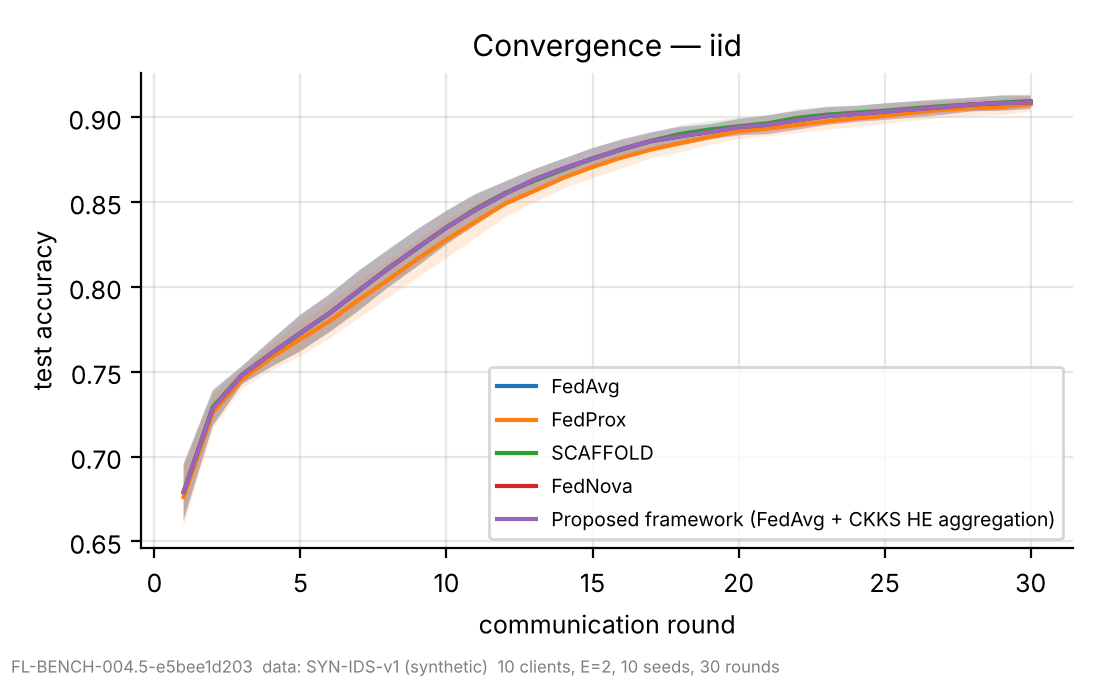

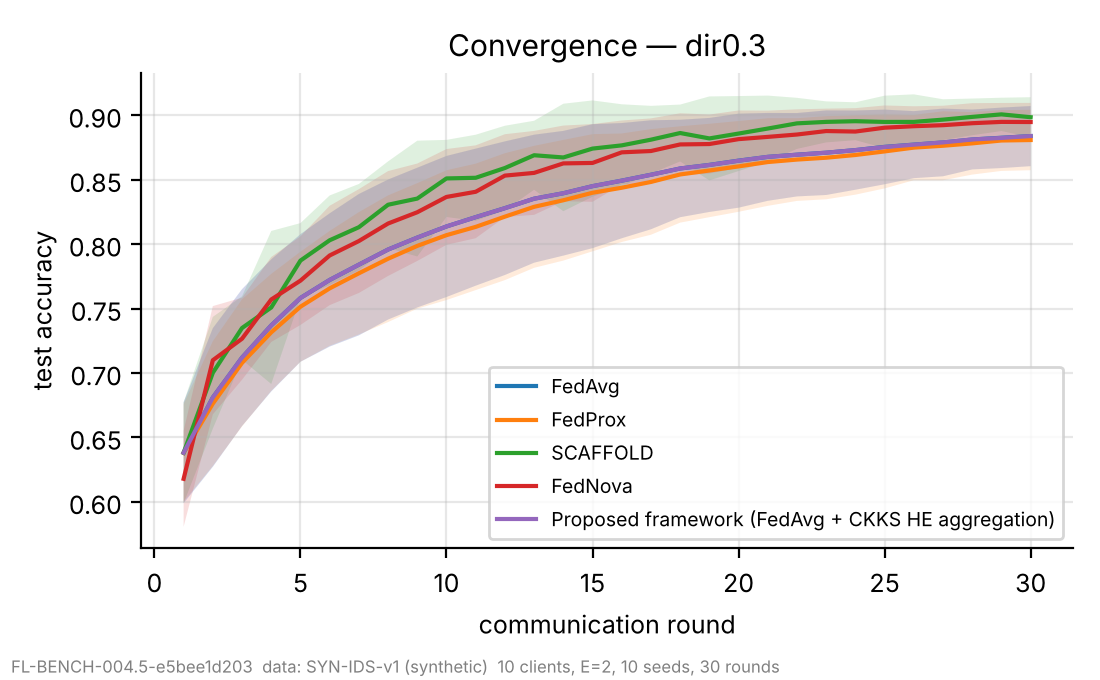

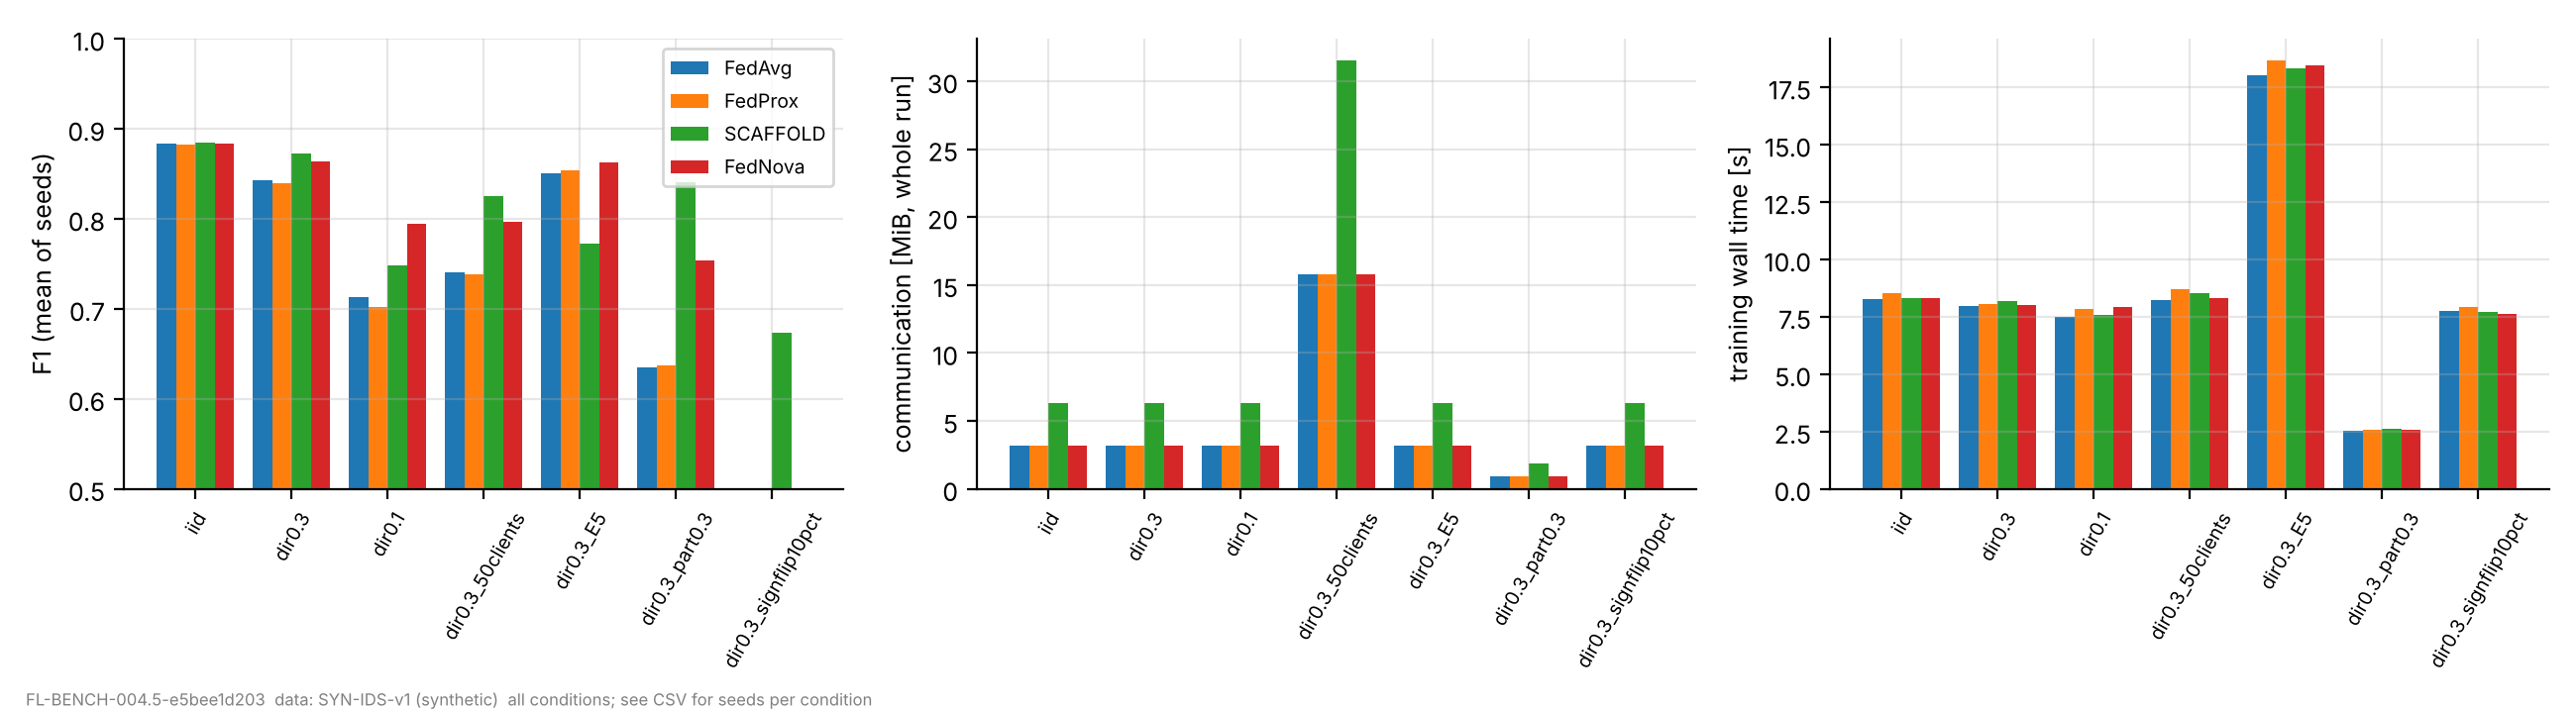

In [10]:
show_fig('task_4_5_convergence_iid.png')
show_fig('task_4_5_convergence_dir0.3.png')
show_fig('task_4_5_summary_bars.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

See printed summary.

In [11]:
d = pd.read_csv(RES / 'task_4_5_summary.csv'); print(d.columns.tolist()); display(d.head(12).round(4))

['condition', 'algo', 'n_seeds', 'acc', 'acc_ci', 'precision', 'precision_ci', 'recall', 'recall_ci', 'f1', 'f1_ci', 'auc', 'auc_ci', 'pr_auc', 'pr_auc_ci', 'specificity', 'specificity_ci', 'ece', 'ece_ci', 'loss', 'loss_ci', 'comm_mb', 'comm_mb_ci', 'train_wall_s', 'train_wall_s_ci', 'cpu_time_s', 'cpu_time_s_ci', 'rounds_to_target_mean', 'target_reached_frac']


,condition,algo,n_seeds,acc,acc_ci,precision,precision_ci,recall,recall_ci,f1,f1_ci,auc,auc_ci,pr_auc,pr_auc_ci,specificity,specificity_ci,ece,ece_ci,loss,loss_ci,comm_mb,comm_mb_ci,train_wall_s,train_wall_s_ci,cpu_time_s,cpu_time_s_ci,rounds_to_target_mean,target_reached_frac
0,iid,fedavg,10,0.9088,"[0.9058, 0.9118]",0.9048,"[0.9007, 0.9089]",0.8642,"[0.8594, 0.8691]",0.8840,"[0.8802, 0.8879]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9388,"[0.9360, 0.9416]",0.0221,"[0.0200, 0.0242]",0.2379,"[0.2336, 0.2422]",3.1540,"[3.1540, 3.1540]",8.2729,"[7.8963, 8.6496]",8.205,"[7.8245, 8.5855]",11.8,1.0
1,iid,fedprox,10,0.9076,"[0.9044, 0.9109]",0.9040,"[0.8998, 0.9082]",0.8619,"[0.8560, 0.8679]",0.8824,"[0.8781, 0.8868]",0.9636,"[0.9623, 0.9650]",0.9487,"[0.9468, 0.9507]",0.9384,"[0.9355, 0.9412]",0.0252,"[0.0230, 0.0274]",0.2418,"[0.2375, 0.2461]",3.1540,"[3.1540, 3.1540]",8.5312,"[7.9704, 9.0920]",8.474,"[7.9129, 9.0351]",12.6,1.0
2,iid,scaffold,10,0.9095,"[0.9065, 0.9125]",0.9059,"[0.9012, 0.9106]",0.8649,"[0.8607, 0.8692]",0.8849,"[0.8811, 0.8887]",0.9650,"[0.9637, 0.9663]",0.9504,"[0.9486, 0.9523]",0.9395,"[0.9363, 0.9428]",0.0277,"[0.0253, 0.0301]",0.2380,"[0.2339, 0.2420]",6.3080,"[6.3080, 6.3080]",8.3072,"[7.9388, 8.6756]",8.249,"[7.8806, 8.6174]",11.8,1.0
3,iid,fednova,10,0.9088,"[0.9058, 0.9118]",0.9049,"[0.9006, 0.9091]",0.8642,"[0.8594, 0.8690]",0.8840,"[0.8802, 0.8879]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9388,"[0.9360, 0.9417]",0.0224,"[0.0202, 0.0246]",0.2379,"[0.2336, 0.2422]",3.1540,"[3.1540, 3.1540]",8.3269,"[7.9790, 8.6747]",8.271,"[7.9172, 8.6248]",11.8,1.0
4,iid,proposed,10,0.9089,"[0.9058, 0.9119]",0.9050,"[0.9008, 0.9092]",0.8642,"[0.8593, 0.8690]",0.8841,"[0.8802, 0.8880]",0.9646,"[0.9633, 0.9660]",0.9499,"[0.9479, 0.9518]",0.9389,"[0.9361, 0.9418]",0.0223,"[0.0200, 0.0245]",0.2379,"[0.2336, 0.2422]",96.3823,"[96.3719, 96.3927]",11.2263,"[10.8181, 11.6344]",11.145,"[10.7311, 11.5589]",11.8,1.0
5,dir0.3,fedavg,10,0.8839,"[0.8663, 0.9015]",0.9137,"[0.8965, 0.9308]",0.7879,"[0.7288, 0.8470]",0.8431,"[0.8124, 0.8737]",0.9550,"[0.9485, 0.9615]",0.9371,"[0.9294, 0.9448]",0.9485,"[0.9348, 0.9621]",0.0451,"[0.0203, 0.0699]",0.2835,"[0.2523, 0.3147]",3.1540,"[3.1540, 3.1540]",7.9543,"[7.5873, 8.3214]",7.907,"[7.5367, 8.2773]",16.8,0.8
6,dir0.3,fedprox,10,0.8808,"[0.8632, 0.8985]",0.9091,"[0.8955, 0.9228]",0.7834,"[0.7277, 0.8392]",0.8391,"[0.8088, 0.8693]",0.9526,"[0.9448, 0.9605]",0.9341,"[0.9245, 0.9437]",0.9464,"[0.9351, 0.9576]",0.0426,"[0.0207, 0.0645]",0.2865,"[0.2541, 0.3188]",3.1540,"[3.1540, 3.1540]",8.0590,"[7.7518, 8.3662]",8.020,"[7.7153, 8.3247]",18.0,0.8
7,dir0.3,scaffold,10,0.8986,"[0.8868, 0.9103]",0.8839,"[0.8561, 0.9116]",0.8636,"[0.8481, 0.8791]",0.8729,"[0.8606, 0.8852]",0.9593,"[0.9529, 0.9656]",0.9430,"[0.9353, 0.9508]",0.9221,"[0.8991, 0.9451]",0.0305,"[0.0178, 0.0433]",0.2679,"[0.2384, 0.2974]",6.3080,"[6.3080, 6.3080]",8.1876,"[7.6397, 8.7354]",8.157,"[7.6185, 8.6955]",11.4,1.0
8,dir0.3,fednova,10,0.8948,"[0.8836, 0.9060]",0.9020,"[0.8752, 0.9288]",0.8320,"[0.7935, 0.8706]",0.8637,"[0.8471, 0.8803]",0.9592,"[0.9547, 0.9638]",0.9424,"[0.9370, 0.9477]",0.9370,"[0.9141, 0.9600]",0.0354,"[0.0201, 0.0508]",0.2636,"[0.2437, 0.2835]",3.1540,"[3.1540, 3.1540]",8.0003,"[7.5914, 8.4093]",7.964,"[7.5503, 8.3777]",12.8,1.0
9,dir0.3,proposed,10,0.8839,"[0.8663, 0.9015]",0.9137,"[0.8966, 0.9307]",0.7880,"[0.7288, 0.8471]",0.8431,"[0.8124, 0.8738]",0.9550,"[0.9485, 0.9615]",0.9371,"[0.9294, 0.9449]",0.9485,"[0.9349, 0.9620]",0.0451,"[0.0203, 0.0699]",0.2835,"[0.2523, 0.3147]",96.3944,"[96.3807, 96.4081]",11.2549,"[10.8063, 11.7035]",11.192,"[10.7475, 11.6365]",16.8,0.8


## 16. Limitations
- Synthetic tabular data; small MLP.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Implementation validated by identity tests (tests/ and task JSON).

**Jira acceptance:** see `docs/fl_bench_004/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`mcmahan2017`, `li2020fedprox`, `karimireddy2020`, `wang2020fednova`, `li2021niid` — details in `docs/fl_bench_004/references.md`.